---

# Conference Popularity and Association Pattern Mining pada Dataset DBLP

*Notebook 06: Task 6, Algorithm Performance Comparison.*

---

## Kelompok Tugas Besar Data Mining

- Izhar Alif Akbar (18223129)
- Harfhan Ikhtiar (18223123)
- Mahesa Andre (13523140)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Algoritma yang Dibandingkan**](#3)
4. [**Pengukuran**](#4)
5. [**Jumlah Frequent Itemsets**](#5)
6. [**Jumlah Association Rules**](#6)
7. [**Waktu Eksekusi**](#7)
8. [**Jawaban Pertanyaan Task 6**](#8)
9. [**Ringkasan dan Langkah Berikutnya**](#9)

---

# Introduction <a name="1"></a>

---

## Overview

*Task 6 membandingkan Apriori (notebook `03_apriori`) dan FP-Growth (notebook `04_fpgrowth`) pada author-based transactional database dan keempat min support yang sama dengan Task 4.*

## Aim

*Mengukur untuk setiap min support (0,1%, 0,5%, 1%, 2%): jumlah frequent itemsets, jumlah association rules (min confidence 50%), dan waktu eksekusi kedua algoritma.*

*Menjawab tiga pertanyaan: (1) bagaimana perubahan min support memengaruhi performa kedua algoritma, (2) apakah kedua algoritma menghasilkan frequent itemsets yang sama, dan (3) algoritma mana yang lebih sesuai untuk dataset DBLP.*

## Approach

*Kedua algoritma menerima masukan yang sama, yaitu list frozenset kode item dari `tx_author.parquet`, dan memakai ambang yang sama (`min_count_for`: bilangan bulat terkecil c dengan c / N ≥ min support). Waktu diukur dengan jam dinding di sekitar pemanggilan fungsi, sehingga pemuatan Parquet dan pembentukan list tidak dihitung. Setiap kombinasi algoritma dan min support dijalankan beberapa kali, dan yang dilaporkan adalah median, minimum, dan maksimum. Untuk FP-Growth, waktu pembentukan FP-tree dan waktu penambangan juga dilaporkan terpisah.*

*Jumlah rules dihitung dengan `src/rules.py` yang sama untuk kedua algoritma, sehingga perbedaan jumlah rules hanya dapat berasal dari perbedaan frequent itemsets.*

---

# Initialization <a name="2"></a>

---

## Environment Setup

Notebook ini tidak memakai GPU. Prasyaratnya adalah notebook `02_transactions` sudah dijalankan sehingga `data/processed/tx_author.parquet` tersedia.

Sel berikut memasang semua pustaka yang dipakai notebook ini.

In [1]:
%pip install -q --disable-pip-version-check numpy pandas scipy matplotlib pyarrow mlxtend

Note: you may need to restart the kernel to use updated packages.


## Import Libraries

Seluruh `import` untuk notebook ini dikumpulkan di satu sel. Modul proyek di `src/` diimpor setelah `Settings` menetapkan path-nya.

In [2]:
import os
import random
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

## Seed Everything

Kedua algoritma deterministik. Seed tetap ditetapkan agar konsisten dengan notebook lain.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Seluruh path, ambang, jumlah pengulangan, dan warna dipusatkan di kelas `Settings`. Palet warna sama dengan notebook sebelumnya.

In [4]:
class Settings:
    SEED = 42
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

    SRC_DIR = ROOT / "src"
    PROC_DIR = ROOT / "data" / "processed"
    TAB_DIR = ROOT / "outputs" / "tables"
    FIG_DIR = ROOT / "outputs" / "figures"

    ITEMS = PROC_DIR / "tx_items.csv"
    TX_AUTHOR = PROC_DIR / "tx_author.parquet"

    MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
    MIN_CONFIDENCE = 0.5
    REPEATS = 3

    INK = "#0b0b0b"
    INK_2 = "#52514e"
    MUTED = "#898781"
    GRID = "#e1e0d9"
    BASELINE = "#c3c2b7"
    SURFACE = "#fcfcfb"
    BLUE = "#2a78d6"
    BLUE_LIGHT = "#9ec5f4"
    ORANGE = "#eb6834"
    GRAY = "#b9b8b2"

CFG = Settings()
for d in (CFG.TAB_DIR, CFG.FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(CFG.SRC_DIR))
from benchmark import load_apriori, time_runs
from fpgrowth import fpgrowth
from fpm_data import load_horizontal, load_item_names
from rules import generate_rules
from validation import compare_itemsets, compare_rules

Gaya grafik dan fungsi bantu diatur sekali di sini. Angka ditulis dengan pemisah ribuan titik dan desimal koma agar konsisten dengan notebook sebelumnya.

In [5]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": CFG.SURFACE, "axes.facecolor": CFG.SURFACE, "savefig.facecolor": CFG.SURFACE,
    "font.size": 9.5, "text.color": CFG.INK, "axes.labelcolor": CFG.INK_2,
    "xtick.color": CFG.INK_2, "ytick.color": CFG.INK_2, "axes.edgecolor": CFG.BASELINE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": CFG.GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)


def fmt_id(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", "X").replace(".", ",").replace("X", ".")


def pct_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",") + "%"


def save_fig(fig, name):
    fig.savefig(CFG.FIG_DIR / name)
    plt.show()


def save_table(df, name, index=True):
    df.to_csv(CFG.TAB_DIR / name, index=index)

## Load Dataset

Tabel panjang author-based diubah ke bentuk horizontal sekali, lalu dipakai bersama oleh kedua algoritma. Waktu pemuatan tidak termasuk pengukuran.

In [6]:
transactions = load_horizontal(CFG.TX_AUTHOR)
names = load_item_names(CFG.ITEMS)
N = len(transactions)
print(f"Transaksi: {fmt_id(N)} | item unik: {fmt_id(len(names))}")

Transaksi: 1.821.757 | item unik: 4.373


---

# Algoritma yang Dibandingkan <a name="3"></a>

---

Apriori dibaca dari `src/apriori.py` (notebook `03_apriori`). Jika file itu belum ada, `load_apriori` memakai **pengganti sementara** yang hanya memanggil FP-Growth, agar seluruh alur notebook ini dapat diuji. Selama pengganti sementara dipakai, angka Apriori di notebook ini **bukan hasil Apriori** dan tidak boleh dipakai untuk menjawab pertanyaan Task 6. Setiap tabel menyimpan kolom `sumber_apriori` agar asal angkanya selalu jelas.

In [7]:
apriori_fn, APRIORI_STANDIN = load_apriori()
SUMBER_APRIORI = "PENGGANTI SEMENTARA (FP-Growth)" if APRIORI_STANDIN else "src/apriori.py"
algorithms = {
    "Apriori": apriori_fn,
    "FP-Growth": lambda tx, ms: fpgrowth(tx, ms, keep_tree=False),
}
if APRIORI_STANDIN:
    print("PERINGATAN: src/apriori.py belum ada. Kolom Apriori memakai pengganti sementara (FP-Growth).")
    print("Angka Apriori di notebook ini BUKAN hasil Apriori dan hanya menguji alur notebook.")
print(f"Sumber Apriori: {SUMBER_APRIORI}")

PERINGATAN: src/apriori.py belum ada. Kolom Apriori memakai pengganti sementara (FP-Growth).
Angka Apriori di notebook ini BUKAN hasil Apriori dan hanya menguji alur notebook.
Sumber Apriori: PENGGANTI SEMENTARA (FP-Growth)


---

# Pengukuran <a name="4"></a>

---

Setiap algoritma dijalankan `REPEATS` kali untuk setiap min support. Hasil setiap pengulangan diperiksa sama persis. Waktu setiap run disimpan apa adanya di `t6_waktu_mentah.csv`.

In [8]:
runs = []
found = {}
for ms in CFG.MIN_SUPPORTS:
    for name, fn in algorithms.items():
        timed, itemsets = time_runs(name, fn, transactions, ms, CFG.REPEATS)
        runs.extend(timed)
        found[(name, ms)] = itemsets
        median = np.median([r.seconds for r in timed])
        print(f"min_sup {pct_id(ms * 100)} | {name:9s} | {fmt_id(len(itemsets))} itemsets | median {median:.2f} s")

raw = pd.DataFrame([asdict(r) for r in runs])
raw["sumber_apriori"] = SUMBER_APRIORI
save_table(raw, "t6_waktu_mentah.csv", index=False)

min_sup 0,1% | Apriori   | 1.514 itemsets | median 11.85 s


min_sup 0,1% | FP-Growth | 1.514 itemsets | median 12.02 s


min_sup 0,5% | Apriori   | 88 itemsets | median 3.27 s


min_sup 0,5% | FP-Growth | 88 itemsets | median 3.22 s


min_sup 1,0% | Apriori   | 30 itemsets | median 2.40 s


min_sup 1,0% | FP-Growth | 30 itemsets | median 2.43 s


min_sup 2,0% | Apriori   | 6 itemsets | median 1.93 s


min_sup 2,0% | FP-Growth | 6 itemsets | median 1.96 s


---

# Jumlah Frequent Itemsets <a name="5"></a>

---

Untuk setiap min support, jumlah frequent itemsets kedua algoritma dibandingkan, lalu himpunan itemset dan count-nya dicocokkan satu per satu.

In [9]:
item_rows = []
for ms in CFG.MIN_SUPPORTS:
    a, f = found[("Apriori", ms)], found[("FP-Growth", ms)]
    cmp = compare_itemsets(a, f)
    item_rows.append({"min_support": ms, "itemsets_apriori": len(a), "itemsets_fpgrowth": len(f),
                      "hanya_apriori": cmp["extra"], "hanya_fpgrowth": cmp["missing"],
                      "count_berbeda": cmp["count_mismatch"], "identik": cmp["identical"]})
item_cmp = pd.DataFrame(item_rows)
item_cmp["sumber_apriori"] = SUMBER_APRIORI
save_table(item_cmp, "t6_perbandingan_itemset.csv", index=False)
item_cmp

,min_support,itemsets_apriori,itemsets_fpgrowth,hanya_apriori,hanya_fpgrowth,count_berbeda,identik,sumber_apriori
0,0.001,1514,1514,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)
1,0.005,88,88,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)
2,0.010,30,30,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)
3,0.020,6,6,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)


---

# Jumlah Association Rules <a name="6"></a>

---

Rules dibangkitkan dari frequent itemsets masing-masing algoritma dengan `src/rules.py` dan min confidence 50%, lalu dibandingkan.

In [10]:
def as_rule_dict(df):
    cols = ["antecedent", "consequent", "support", "confidence", "lift"]
    return {(frozenset(a), frozenset(c)): (s, cf, l) for a, c, s, cf, l in df[cols].itertuples(index=False)}

rule_rows = []
for ms in CFG.MIN_SUPPORTS:
    ra = generate_rules(found[("Apriori", ms)], N, CFG.MIN_CONFIDENCE)
    rf = generate_rules(found[("FP-Growth", ms)], N, CFG.MIN_CONFIDENCE)
    cmp = compare_rules(ra, as_rule_dict(rf))
    rule_rows.append({"min_support": ms, "rules_apriori": len(ra), "rules_fpgrowth": len(rf),
                      "hanya_apriori": cmp["extra"], "hanya_fpgrowth": cmp["missing"],
                      "metrik_berbeda": cmp["metric_mismatch"], "identik": cmp["identical"]})
rule_cmp = pd.DataFrame(rule_rows)
rule_cmp["sumber_apriori"] = SUMBER_APRIORI
save_table(rule_cmp, "t6_perbandingan_rules.csv", index=False)
rule_cmp

,min_support,rules_apriori,rules_fpgrowth,hanya_apriori,hanya_fpgrowth,metrik_berbeda,identik,sumber_apriori
0,0.001,1387,1387,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)
1,0.005,7,7,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)
2,0.010,1,1,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)
3,0.020,0,0,0,0,0,True,PENGGANTI SEMENTARA (FP-Growth)


---

# Waktu Eksekusi <a name="7"></a>

---

Tabel berikut meringkas waktu setiap kombinasi: median, minimum, dan maksimum dari seluruh pengulangan. Kolom `rasio_apriori_fpgrowth` adalah median Apriori dibagi median FP-Growth; nilai di atas 1 berarti FP-Growth lebih cepat. Untuk FP-Growth, median waktu pembentukan FP-tree dan penambangan ditampilkan terpisah.

In [11]:
summary = (raw.groupby(["min_support", "algorithm"])
              .agg(median_s=("seconds", "median"), min_s=("seconds", "min"), max_s=("seconds", "max"),
                   t_build_median_s=("t_build", "median"), t_mine_median_s=("t_mine", "median"),
                   itemsets=("n_itemsets", "first"))
              .reset_index())
ratio = summary.pivot(index="min_support", columns="algorithm", values="median_s")
summary = summary.merge((ratio["Apriori"] / ratio["FP-Growth"]).rename("rasio_apriori_fpgrowth").reset_index(),
                        on="min_support")
summary["sumber_apriori"] = SUMBER_APRIORI
save_table(summary, "t6_waktu_ringkasan.csv", index=False)
summary.style.format({"median_s": "{:.2f}", "min_s": "{:.2f}", "max_s": "{:.2f}", "t_build_median_s": "{:.2f}",
                      "t_mine_median_s": "{:.2f}", "rasio_apriori_fpgrowth": "{:.2f}"}, na_rep="-")

,min_support,algorithm,median_s,min_s,max_s,t_build_median_s,t_mine_median_s,itemsets,rasio_apriori_fpgrowth,sumber_apriori
0,0.001000,Apriori,11.85,11.50,12.03,6.32,5.57,1514,0.99,PENGGANTI SEMENTARA (FP-Growth)
1,0.001000,FP-Growth,12.02,11.41,12.09,6.28,5.76,1514,0.99,PENGGANTI SEMENTARA (FP-Growth)
2,0.005000,Apriori,3.27,3.25,3.33,2.58,0.68,88,1.02,PENGGANTI SEMENTARA (FP-Growth)
3,0.005000,FP-Growth,3.22,3.19,3.31,2.55,0.67,88,1.02,PENGGANTI SEMENTARA (FP-Growth)
4,0.010000,Apriori,2.40,2.34,2.41,2.24,0.15,30,0.99,PENGGANTI SEMENTARA (FP-Growth)
5,0.010000,FP-Growth,2.43,2.41,2.46,2.27,0.15,30,0.99,PENGGANTI SEMENTARA (FP-Growth)
6,0.020000,Apriori,1.93,1.89,2.07,1.93,0.00,6,0.99,PENGGANTI SEMENTARA (FP-Growth)
7,0.020000,FP-Growth,1.96,1.95,1.98,1.96,0.00,6,0.99,PENGGANTI SEMENTARA (FP-Growth)


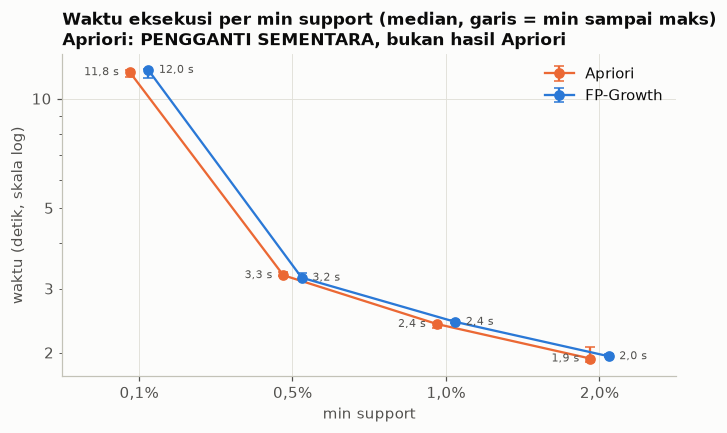

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
x = np.arange(len(CFG.MIN_SUPPORTS))
for name, color, offset, side in (("Apriori", CFG.ORANGE, -0.06, -1), ("FP-Growth", CFG.BLUE, 0.06, 1)):
    s = summary[summary["algorithm"] == name].set_index("min_support").loc[CFG.MIN_SUPPORTS]
    err = np.vstack([s["median_s"] - s["min_s"], s["max_s"] - s["median_s"]])
    ax.errorbar(x + offset, s["median_s"], yerr=err, marker="o", color=color, capsize=3, label=name)
    for xi, v in zip(x + offset, s["median_s"]):
        ax.annotate(f"{fmt_id(v, 1)} s", (xi, v), xytext=(7 * side, 0), textcoords="offset points",
                    ha="left" if side > 0 else "right", va="center", fontsize=7.5, color=CFG.INK_2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_id(v, 0 if v >= 1 else 1)))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: fmt_id(v, 0 if v >= 1 else 1) if round(v, 1) in (2, 3, 5, 20, 30, 50) else ""))
ax.set_xticks(x, [pct_id(ms * 100) for ms in CFG.MIN_SUPPORTS])
ax.set_xlim(-0.5, len(x) - 0.5)
ax.set_xlabel("min support")
ax.set_ylabel("waktu (detik, skala log)")
title = "Waktu eksekusi per min support (median, garis = min sampai maks)"
if APRIORI_STANDIN:
    title += "\nApriori: PENGGANTI SEMENTARA, bukan hasil Apriori"
ax.set_title(title)
ax.legend()
save_fig(fig, "t6_waktu_per_min_support.png")

---

# Jawaban Pertanyaan Task 6 <a name="8"></a>

---

**Belum diisi.** Jawaban ketiga pertanyaan Task 6 ditulis setelah Apriori dari notebook `03_apriori` tersedia di `src/apriori.py` dan notebook ini dijalankan ulang. Selama sel di bagian 3 mencetak peringatan pengganti sementara, angka Apriori di atas tidak boleh dipakai.

---

# Ringkasan dan Langkah Berikutnya <a name="9"></a>

---

Notebook ini sudah menyiapkan seluruh pengukuran Task 6: jumlah frequent itemsets, jumlah rules, kesamaan hasil, dan waktu eksekusi berulang untuk keempat min support. Langkah berikutnya adalah menambahkan `src/apriori.py` (kontraknya diuji oleh `tests/test_apriori_contract.py`), menjalankan ulang notebook ini, lalu menulis jawaban bagian 8 berdasarkan angka yang dihasilkan.